Projeto 01 - Análise Exploratória de Dados Olist
Objetivo
Analisar os dados de pedidos do marketplace Olist para entender padrões de vendas, qualidade dos dados e oportunidades de negócio.

# Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [2]:
os.listdir("../data")

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

Carregamento dos dados
Nesta etapa carregamos a base de pedidos do dataset Olist para entender a estrutura das informações.

In [3]:

orders = pd.read_csv("../data/olist_orders_dataset.csv")

Primeiras Linhas

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Análise de Valores Nulos

A base apresenta dados faltantes principalmente relacionados ao fluxo de entrega.

Os maiores volumes de valores nulos estão nas colunas:

- order_delivered_customer_date
- order_delivered_carrier_date

Isso pode indicar pedidos cancelados, pedidos em andamento ou registros de entrega não concluídos.

As colunas fundamentais para identificação dos pedidos e clientes não apresentam valores ausentes.

--------------------------------------------------------------------------

Esse é um dos gráficos mais importantes do dataset Olist.

Ele vai responder:

Quantos pedidos foram entregues?
Quantos foram cancelados?
Quantos estão em transporte?
Quantos estão processando?

In [7]:
status_pedidos = orders["order_status"].value_counts()

total_pedidos = status_pedidos.sum()

for status, quantidade in status_pedidos.items():

    percentual = (
        quantidade / total_pedidos
    ) * 100

    print(
        f"📦 {status}: "
        f"{quantidade:,} pedidos "
        f"({percentual:.1f}%)"
        .replace(",", ".")
    )

📦 delivered: 96.478 pedidos (97.0%)
📦 shipped: 1.107 pedidos (1.1%)
📦 canceled: 625 pedidos (0.6%)
📦 unavailable: 609 pedidos (0.6%)
📦 invoiced: 314 pedidos (0.3%)
📦 processing: 301 pedidos (0.3%)
📦 created: 5 pedidos (0.0%)
📦 approved: 2 pedidos (0.0%)


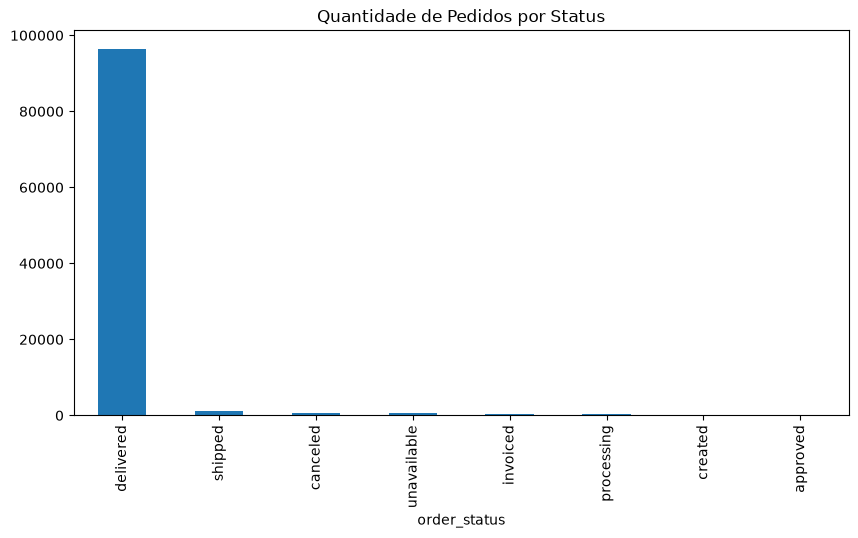

In [8]:
orders["order_status"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Quantidade de Pedidos por Status")


plt.savefig(
    "../images/01_Quantidade_Pedidos_Status.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Análise dos Tempos de Entrega

Nesta etapa vamos calcular o tempo entre a compra e a entrega do pedido, permitindo entender a eficiência logística da operação.

In [9]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [10]:
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days


In [11]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_time_days"
    ]
].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


In [12]:
tempo_entrega = orders["delivery_time_days"]

media = int(tempo_entrega.mean())
mediana = int(tempo_entrega.median())
menor = int(tempo_entrega.min())
maior = int(tempo_entrega.max())

print(f"📦 Tempo médio de entrega: {media} dias")
print(f"📊 Mediana do tempo de entrega: {mediana} dias")

if menor == 0:
    print("⚡ Menor prazo de entrega: no mesmo dia da compra")
else:
    print(f"⚡ Menor prazo de entrega: {menor} dias")

print(f"🚚 Maior prazo de entrega registrado: {maior} dias")

📦 Tempo médio de entrega: 12 dias
📊 Mediana do tempo de entrega: 10 dias
⚡ Menor prazo de entrega: no mesmo dia da compra
🚚 Maior prazo de entrega registrado: 209 dias


Esse gráfico já começa a responder:

Qual o prazo típico de entrega?
Existem entregas muito demoradas?
Existem outliers?

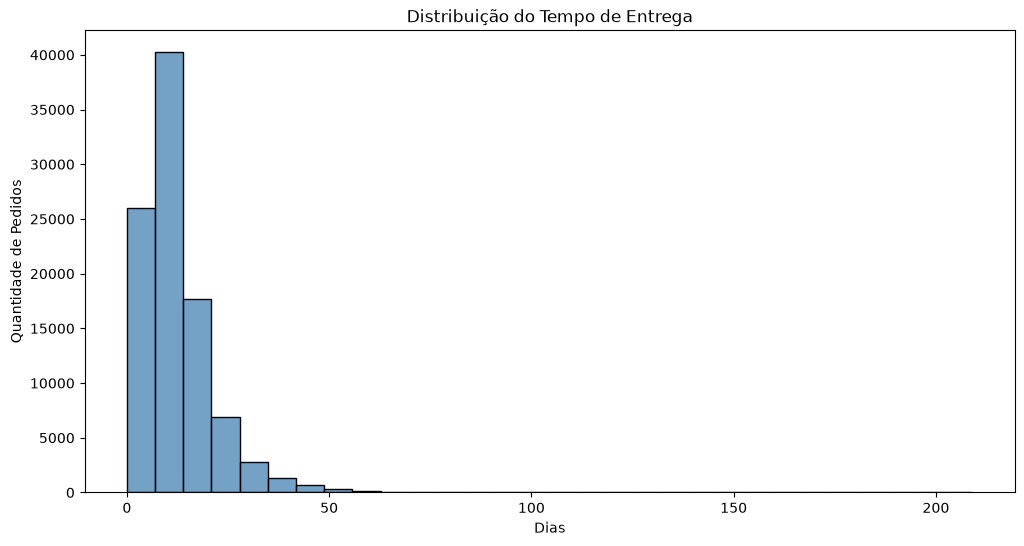

In [13]:
plt.figure(figsize=(12,6))

sns.histplot(
    orders["delivery_time_days"],
    bins=30,
    color="steelblue"
)

plt.title("Distribuição do Tempo de Entrega")
plt.xlabel("Dias")
plt.ylabel("Quantidade de Pedidos")



plt.savefig(
    "../images/02_distribuicao_Tempo_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight Inicial

A distribuição dos tempos de entrega permite identificar o comportamento padrão da operação logística.

Pedidos com prazo muito superior à média podem indicar gargalos operacionais, problemas de transporte ou restrições geográficas.

In [14]:
media_entrega = int(orders["delivery_time_days"].mean())
mediana_entrega = int(orders["delivery_time_days"].median())
maior_entrega = int(orders["delivery_time_days"].max())
menor_entrega = int(orders["delivery_time_days"].min())

print(f"📦 Tempo médio de entrega: {media_entrega} dias")
print(f"📊 Mediana do tempo de entrega: {mediana_entrega} dias")
print(f"🚚 Maior tempo de entrega: {maior_entrega} dias")

if menor_entrega == 0:
    print("⚡ Menor prazo de entrega: no mesmo dia da compra")
else:
    print(f"⚡ Menor prazo de entrega: {menor_entrega} dias")

📦 Tempo médio de entrega: 12 dias
📊 Mediana do tempo de entrega: 10 dias
🚚 Maior tempo de entrega: 209 dias
⚡ Menor prazo de entrega: no mesmo dia da compra


## Principais Métricas de Entrega

Os pedidos foram entregues em média após 12 dias da compra, com mediana de 10 dias.

Também foram identificados casos de entrega realizada no mesmo dia da compra e situações excepcionais que ultrapassaram 200 dias de prazo, indicando a existência de outliers na operação logística.

In [15]:
bins = [0, 3, 7, 14, 30, 60, 365]

labels = [
    "0-3 dias",
    "4-7 dias",
    "8-14 dias",
    "15-30 dias",
    "31-60 dias",
    "60+ dias"
]

orders["delivery_group"] = pd.cut(
    orders["delivery_time_days"],
    bins=bins,
    labels=labels
)

In [16]:
faixas_entrega = (
    orders["delivery_group"]
    .value_counts()
    .sort_index()
)

for faixa, quantidade in faixas_entrega.items():
    print(
        f"📦 Entregas em {faixa}: {quantidade:,}"
        .replace(",", ".")
    )

📦 Entregas em 0-3 dias: 8.589
📦 Entregas em 4-7 dias: 25.096
📦 Entregas em 8-14 dias: 36.398
📦 Entregas em 15-30 dias: 22.262
📦 Entregas em 31-60 dias: 3.830
📦 Entregas em 60+ dias: 288


## Primeira Abordagem: Distribuição do Tempo de Entrega

Inicialmente foi utilizado um histograma para visualizar a distribuição do tempo de entrega dos pedidos.

Embora a visualização represente corretamente os dados, a interpretação não é imediata para usuários de negócio. A presença de valores extremos e a concentração de pedidos em determinadas faixas dificultam a leitura e a extração de insights relevantes.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_12256\1806356077.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


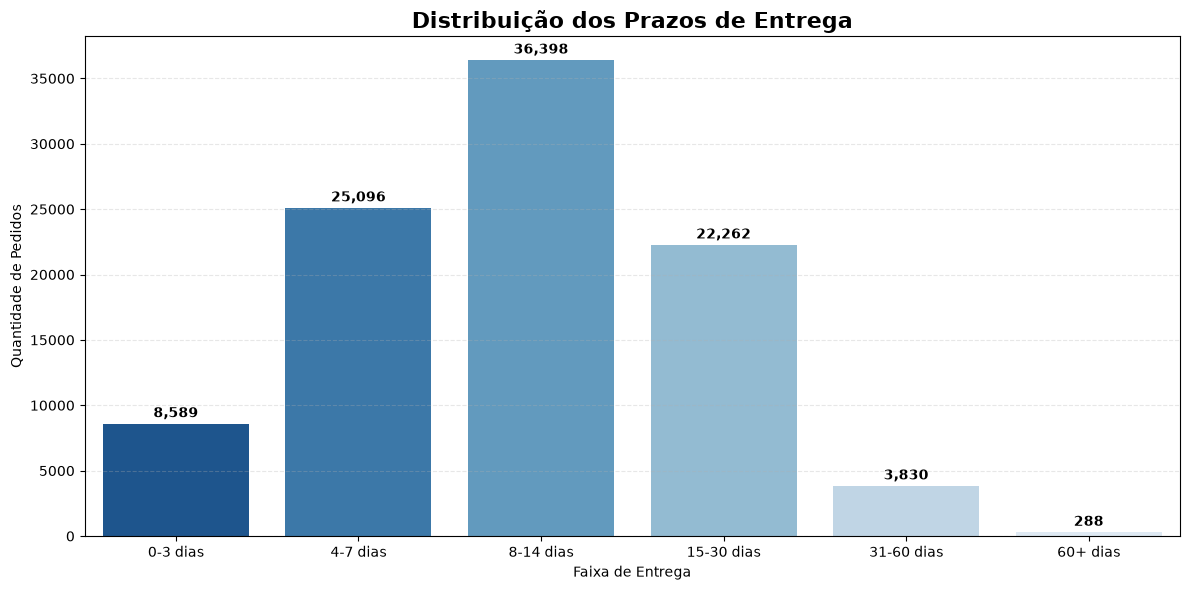

In [17]:
delivery_counts = (
    orders["delivery_group"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    palette="Blues_r"
)

plt.title(
    "Distribuição dos Prazos de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("Quantidade de Pedidos")

for i, v in enumerate(delivery_counts.values):
    ax.text(
        i,
        v + 500,
        f"{v:,.0f}",
        ha="center",
        fontweight="bold"
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()



plt.savefig(
    "../images/03_distribuicao_Prazos_Entrega.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Refinamento da Visualização

Após analisar o histograma, foi identificado que a visualização não comunicava de forma clara o comportamento predominante das entregas.

Para tornar a análise mais intuitiva, os pedidos foram agrupados em faixas de prazo de entrega. Essa abordagem reduz a complexidade visual e facilita a identificação dos períodos com maior concentração de entregas.

Além disso, a nova visualização aproxima a análise da linguagem utilizada por áreas de negócio e operações logísticas, permitindo uma interpretação mais rápida dos resultados.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_12256\2207085768.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


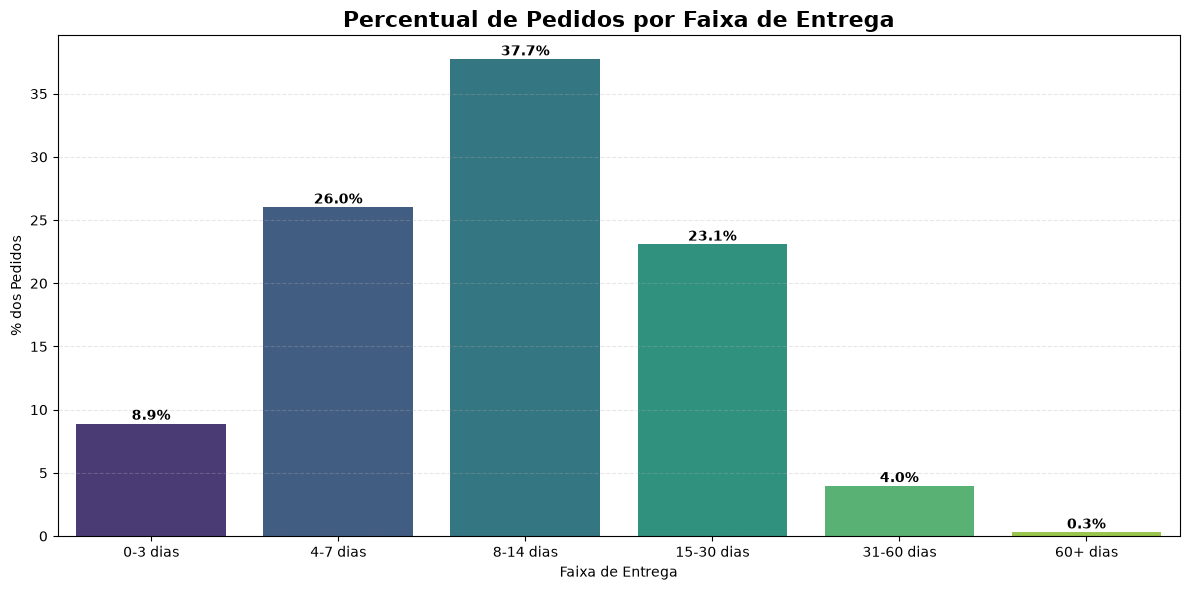

In [18]:
plt.figure(figsize=(12,6))
delivery_pct = (
    orders["delivery_group"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
)

delivery_pct

ax = sns.barplot(
    x=delivery_pct.index,
    y=delivery_pct.values,
    palette="viridis"
)

for i, valor in enumerate(delivery_pct.values):
    ax.text(
        i,
        valor + 0.3,
        f"{valor:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Percentual de Pedidos por Faixa de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("% dos Pedidos")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "../images/04_Percentual_Prazo_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Principais Insights

A visualização por faixas permite observar com maior clareza o comportamento da operação logística.

Os resultados indicam que a maior parte dos pedidos foi entregue entre 8 e 14 dias, seguida pelas entregas realizadas entre 4 e 7 dias.

Também é possível identificar que entregas acima de 60 dias representam uma parcela muito pequena da operação, caracterizando situações excepcionais.

Comparada ao histograma inicial, a categorização por faixas tornou a análise mais acessível e mais adequada para comunicação executiva.

In [19]:
bins = [0, 2, 5, 10, 15, 30, 365]

labels = [
    "Até 2 dias",
    "3-5 dias",
    "6-10 dias",
    "11-15 dias",
    "16-30 dias",
    "Mais de 30 dias"
]

In [20]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

In [21]:
delay = orders["delivery_delay_days"]

media = round(delay.mean(), 1)
mediana = int(delay.median())
menor = int(delay.min())
maior = int(delay.max())

print(f"📦 Média de antecipação/atraso: {media} dias")
print(f"📊 Mediana de antecipação/atraso: {mediana} dias")

if menor < 0:
    print(f"⚡ Maior antecipação registrada: {abs(menor)} dias antes do prazo")
else:
    print(f"⚡ Menor atraso registrado: {menor} dias")

if maior > 0:
    print(f"🚨 Maior atraso registrado: {maior} dias")
else:
    print("✅ Nenhum atraso encontrado")

📦 Média de antecipação/atraso: -11.9 dias
📊 Mediana de antecipação/atraso: -12 dias
⚡ Maior antecipação registrada: 147 dias antes do prazo
🚨 Maior atraso registrado: 188 dias


In [22]:
antes = (delay < 0).sum()
no_prazo = (delay == 0).sum()
atrasado = (delay > 0).sum()

total = antes + no_prazo + atrasado

print(f"✅ Antes do prazo: {(antes/total)*100:.1f}%")
print(f"📅 No prazo: {(no_prazo/total)*100:.1f}%")
print(f"🚨 Atrasado: {(atrasado/total)*100:.1f}%")

✅ Antes do prazo: 91.9%
📅 No prazo: 1.3%
🚨 Atrasado: 6.8%


In [23]:

atrasados = (orders["delivery_delay_days"] > 0).sum()

no_prazo = (orders["delivery_delay_days"] <= 0).sum()

taxa_atraso = (
    (orders["delivery_delay_days"] > 0).mean() * 100
)

print(f"🚨 Pedidos atrasados: {atrasados}")
print(f"✅ Pedidos no prazo: {no_prazo}")
print(f"📦 Taxa de pedidos atrasados: {taxa_atraso:.1f}%")

🚨 Pedidos atrasados: 6535
✅ Pedidos no prazo: 89941
📦 Taxa de pedidos atrasados: 6.6%


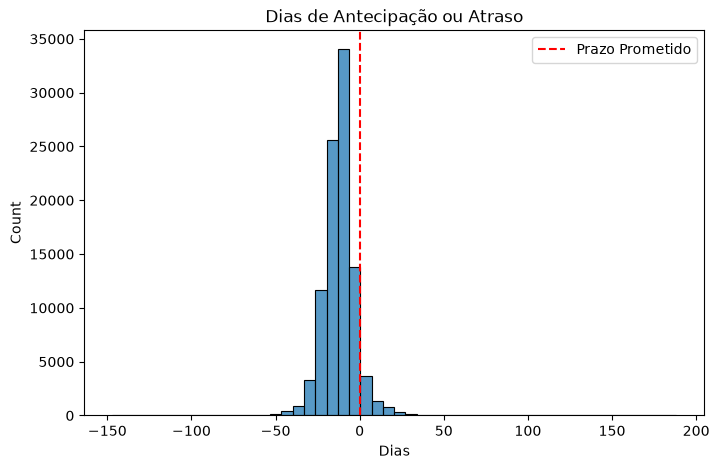

In [24]:
plt.figure(figsize=(8,5))

sns.histplot(
    orders["delivery_delay_days"],
    bins=50
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Prazo Prometido"
)

plt.legend()
plt.title("Dias de Antecipação ou Atraso")
plt.xlabel("Dias")


plt.savefig(
    "../images/05_Dias_Antecipacao_Atraso.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight

A análise dos prazos mostrou que parte dos pedidos foi entregue após a data prometida ao cliente.

Esta métrica é importante para avaliar a eficiência logística e o impacto na experiência do consumidor.

Como os Pedidos Evoluiram ao longo do Tempo ?

In [25]:
orders["order_purchase_year_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [26]:
monthly_orders = (
    orders.groupby("order_purchase_year_month")
    .size()
)

monthly_orders.head()

order_purchase_year_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
Freq: M, dtype: int64

In [27]:
monthly_orders.index = (
    monthly_orders.index
    .to_timestamp()
)

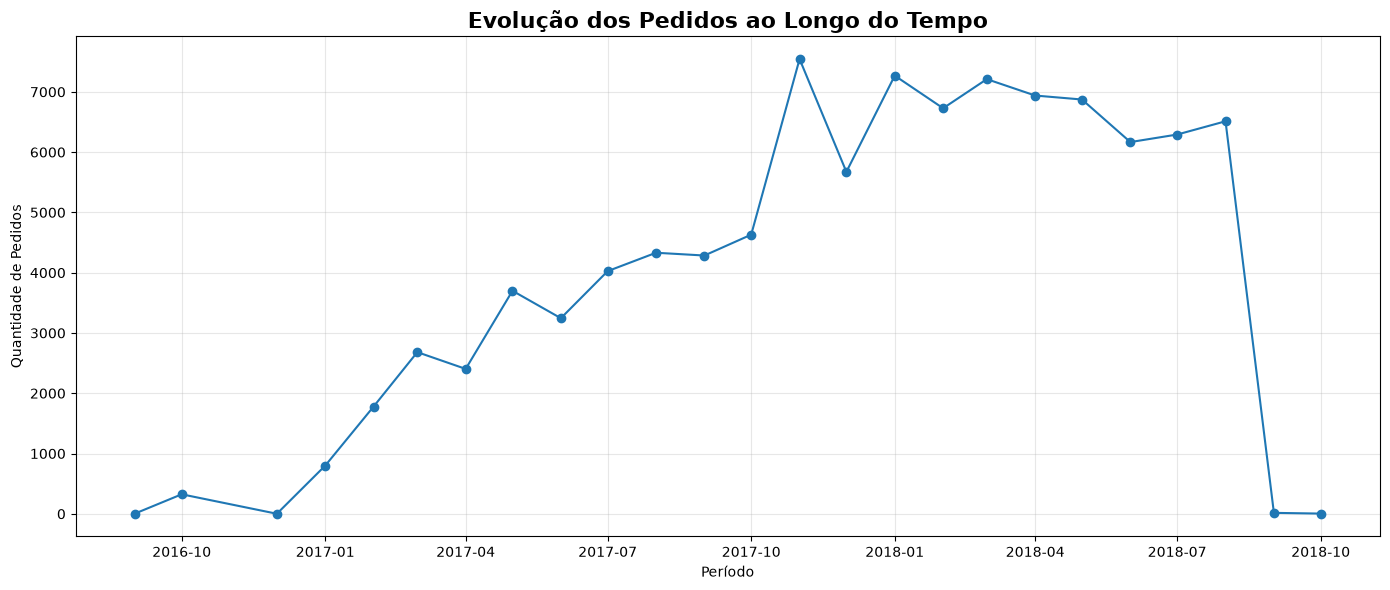

In [28]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o"
)

plt.title(
    "Evolução dos Pedidos ao Longo do Tempo",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Período")
plt.ylabel("Quantidade de Pedidos")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../images/06_evolucao_pedidos_tempo.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Refinamento da Visualização Temporal

A visualização inicial apresentava todos os pedidos do período analisado em uma única série temporal.

Apesar de correta do ponto de vista técnico, essa abordagem dificultava a leitura dos dados, pois os picos de diferentes anos ficavam concentrados no mesmo gráfico.

Para tornar a análise mais intuitiva, optou-se por segmentar os dados por ano e avaliar a distribuição mensal dos pedidos individualmente.

Essa mudança permitiu uma leitura mais clara dos padrões de demanda e facilitou a identificação de possíveis comportamentos sazonais.

In [29]:
orders["ano"] = (
    orders["order_purchase_timestamp"]
    .dt.year
)

In [30]:
orders["ano"].value_counts().sort_index()

ano
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

In [31]:
orders_2016 = orders[
    orders["ano"] == 2016
].copy()

print(f"Quantidade de pedidos em 2016: {len(orders_2016):,}")

Quantidade de pedidos em 2016: 329


In [32]:
orders_2016["mes"] = (
    orders_2016["order_purchase_timestamp"]
    .dt.month
)

In [33]:
pedidos_mes_2016 = (
    orders_2016
    .groupby("mes")
    .size()
)

pedidos_mes_2016

mes
9       4
10    324
12      1
dtype: int64

In [34]:
orders_2017 = orders[
    orders["ano"] == 2017
].copy()


In [35]:
orders_2017["mes"] = (
    orders_2017["order_purchase_timestamp"]
    .dt.month
)

In [36]:
pedidos_mes_2017 = (
    orders_2017
    .groupby("mes")
    .size()
)

pedidos_mes_2017

mes
1      800
2     1780
3     2682
4     2404
5     3700
6     3245
7     4026
8     4331
9     4285
10    4631
11    7544
12    5673
dtype: int64

In [37]:
orders_2018 = orders[
    orders["ano"] == 2018
].copy()


In [38]:
orders_2018["mes"] = (
    orders_2018["order_purchase_timestamp"]
    .dt.month
)

In [39]:
pedidos_mes_2018 = (
    orders_2018
    .groupby("mes")
    .size()
)

pedidos_mes_2018_validos = pedidos_mes_2018.loc[1:8]

In [40]:
pedidos_mes_2018 = (
    orders_2018
    .groupby("mes")
    .size()
)

pedidos_mes_2018 = pedidos_mes_2018.loc[1:8]

pedidos_mes_2018

mes
1    7269
2    6728
3    7211
4    6939
5    6873
6    6167
7    6292
8    6512
dtype: int64

In [41]:
orders_2018[
    "order_purchase_timestamp"
].max()

Timestamp('2018-10-17 17:30:18')

In [42]:
orders_2018[
    "order_purchase_timestamp"
].min()

Timestamp('2018-01-01 02:48:41')

## Início da Operação - 2016

Os dados de 2016 apresentam registros concentrados em poucos meses e com baixo volume de pedidos quando comparados aos anos seguintes.

Devido à quantidade limitada de observações e à forte concentração dos pedidos em um único período, optou-se por não utilizar visualizações gráficas para este ano.

Essa decisão evita interpretações equivocadas e direciona a análise para períodos com maior representatividade estatística.

## Evolução dos Pedidos em 2017

Após avaliar os registros de 2016, observou-se que a quantidade limitada de meses disponíveis não permitia uma análise temporal consistente.

Dessa forma, a análise passa a considerar o ano de 2017, que apresenta uma quantidade maior de registros e permite identificar tendências, crescimento da operação e possíveis padrões ao longo dos meses.

## Análise dos registro de 2017 

O ano de 2017 apresentou registros durante todos os meses, permitindo uma análise temporal mais completa da operação.

Diferentemente de 2016, que possuía uma quantidade reduzida de observações, 2017 possibilita identificar tendências de crescimento e eventuais períodos de maior concentração de pedidos ao longo do ano.


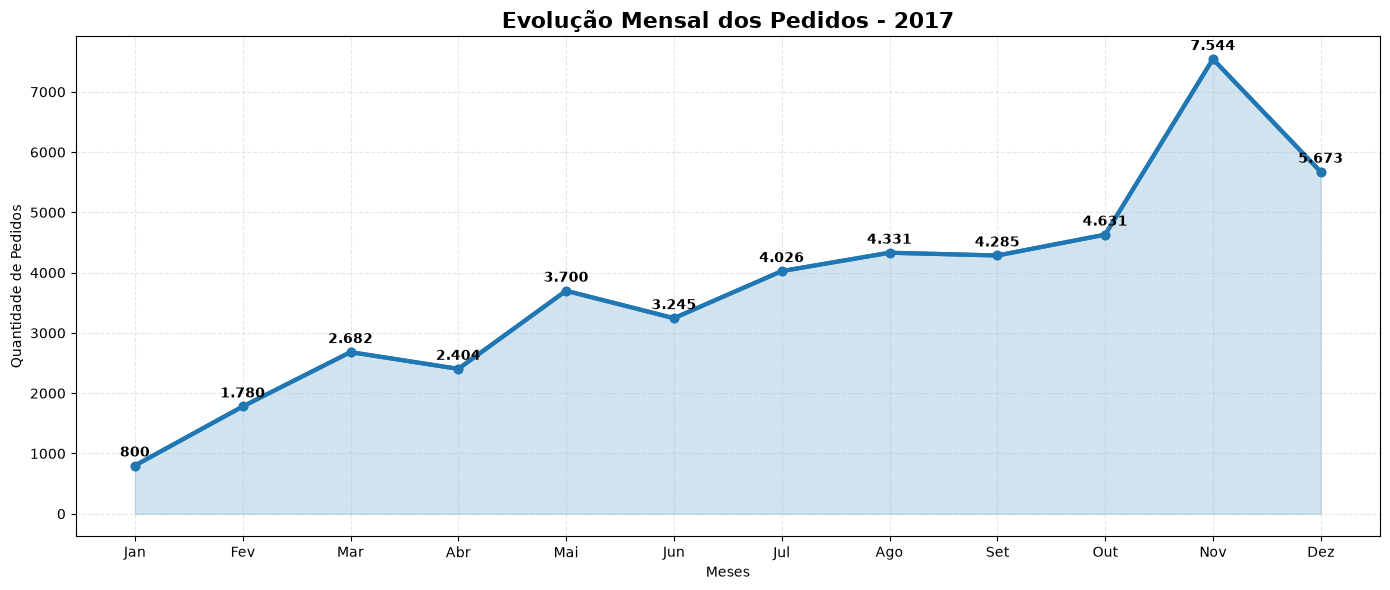

<Figure size 1400x600 with 0 Axes>

In [43]:
plt.figure(figsize=(14,6))

plt.plot(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)

plt.fill_between(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    alpha=0.2,
    color="#1f77b4"
)

plt.plot(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)

for x, y in zip(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values
):
    plt.text(
        x,
        y + 150,
        f"{y:,}".replace(",", "."),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Evolução Mensal dos Pedidos - 2017",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Meses")
plt.ylabel("Quantidade de Pedidos")

plt.grid(
    linestyle="--",
    alpha=0.3
)

meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
]

plt.xticks(
    ticks=range(1,13),
    labels=meses
)
plt.tight_layout()

plt.savefig(
    "../images/07_evolucao_pedidos_2017.png",
    bbox_inches="tight",
    dpi=300
)
plt.figure(figsize=(14,6))



plt.show()

## Tratamento da Série Temporal de 2018

Durante a análise foi observado um volume extremamente reduzido de pedidos nos meses de setembro e outubro de 2018.

Após investigação, verificou-se que os registros disponíveis para esses períodos não representam meses completos, o que poderia gerar interpretações incorretas sobre uma possível queda nas vendas.

Por esse motivo, os meses incompletos foram removidos da análise temporal para preservar a consistência das comparações.

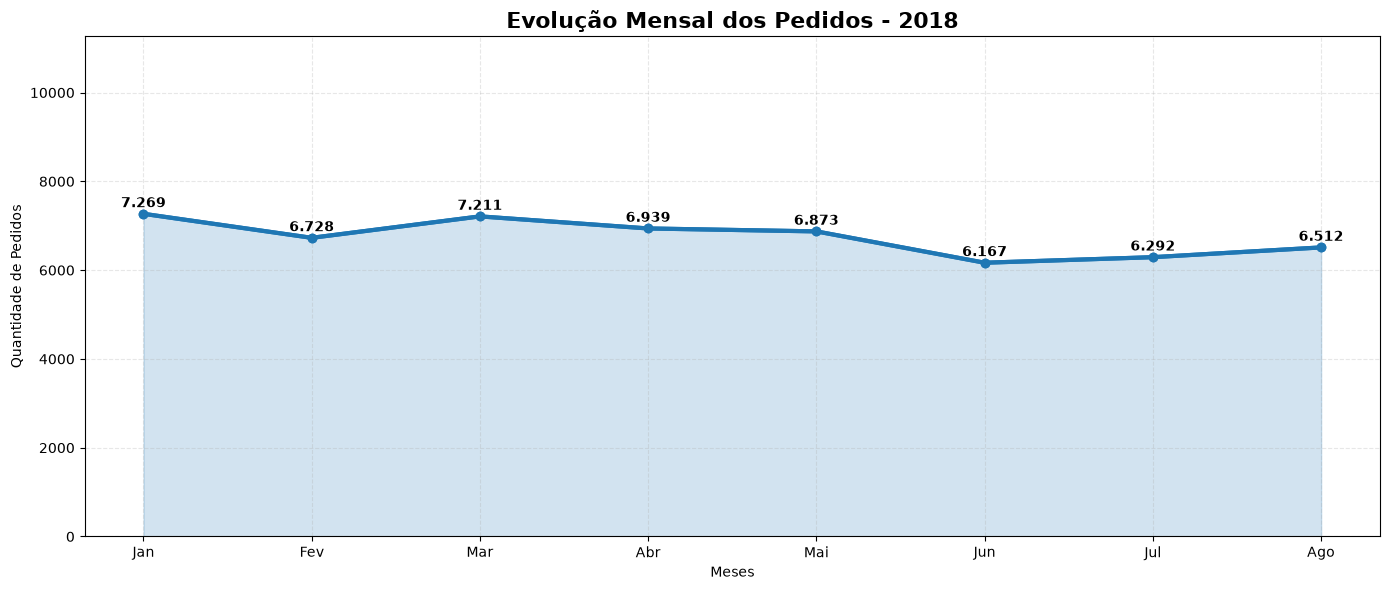

<Figure size 1400x600 with 0 Axes>

In [44]:
plt.figure(figsize=(14,6))

plt.plot(
    pedidos_mes_2018_validos.index,
    pedidos_mes_2018_validos.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)

plt.fill_between(
    pedidos_mes_2018.index,
    pedidos_mes_2018.values,
    alpha=0.2,
    color="#1f77b4"
)

plt.plot(
    pedidos_mes_2018.index,
    pedidos_mes_2018.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)
plt.ylim(
    0,
    max(pedidos_mes_2018.values) * 1.55
)

for x, y in zip(
    pedidos_mes_2018.index,
    pedidos_mes_2018.values
):
    plt.text(
        x,
        y + 150,
        f"{y:,}".replace(",", "."),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Evolução Mensal dos Pedidos - 2018",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Meses")
plt.ylabel("Quantidade de Pedidos")

plt.grid(
    linestyle="--",
    alpha=0.3
)

meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago"
    
]

plt.xticks(
    ticks=range(1,9),
    labels=meses
)
plt.tight_layout()

plt.savefig(
    "../images/08_evolucao_pedidos_2018.png",
    bbox_inches="tight",
    dpi=300
)
plt.figure(figsize=(14,6))



plt.show()

## Análise dos Pedidos em 2018

Os dados de 2018 apresentam um comportamento significativamente diferente do observado em 2017.

Enquanto 2017 mostrou crescimento contínuo ao longo do período analisado, 2018 manteve um volume relativamente estável de pedidos, variando entre aproximadamente 6 mil e 7 mil pedidos por mês.

Esse comportamento sugere uma fase de consolidação da operação, indicando que o marketplace atingiu um patamar de demanda mais consistente ao longo do ano.

Os meses de setembro e outubro foram removidos da análise por apresentarem registros incompletos, evitando interpretações equivocadas sobre possíveis quedas de desempenho.

## Comparação entre 2017 e 2018

Após a análise individual de cada ano, foi realizada uma comparação direta entre os volumes mensais de pedidos.

O objetivo é verificar se o crescimento observado em 2017 foi mantido nos períodos seguintes e identificar possíveis mudanças de comportamento na operação do marketplace.

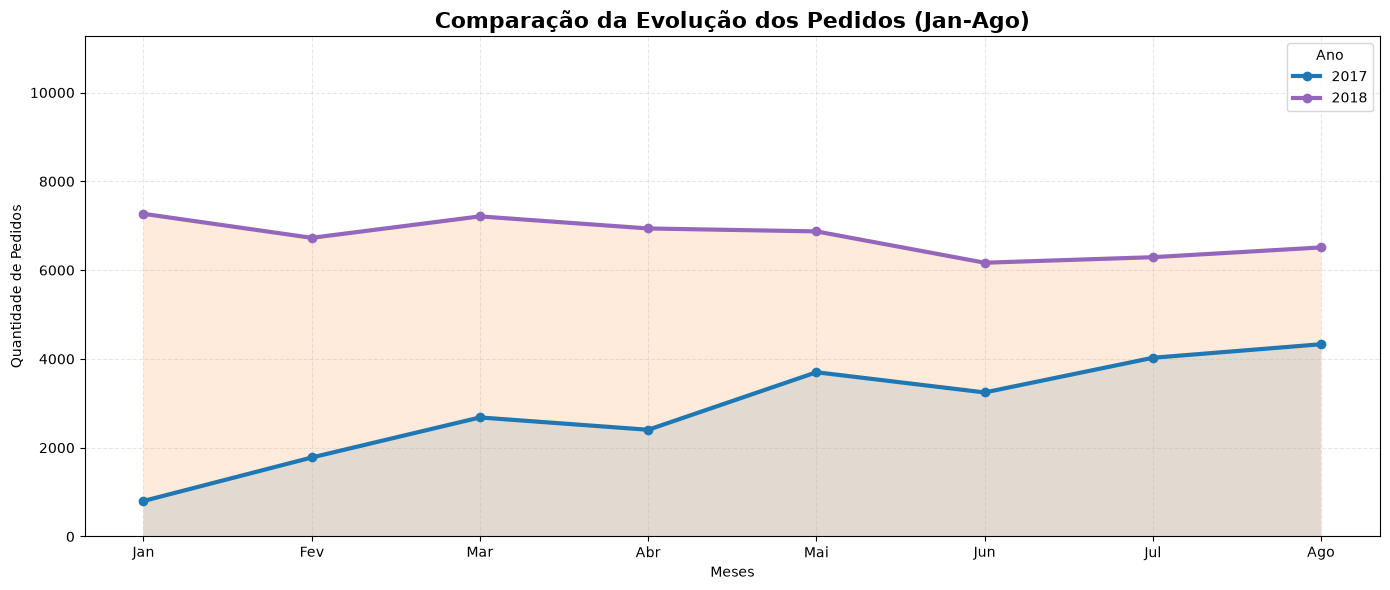

In [45]:
meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago"
]

plt.figure(figsize=(14,6))

# 2017
color="#1f77b4"  # azul

# 2018
color="#9467bd"  # roxo claro

plt.ylim(
    0,
    max(pedidos_mes_2018.values) * 1.55
)


plt.plot(
    pedidos_mes_2017.loc[1:8].index,
    pedidos_mes_2017.loc[1:8].values,
    marker="o",
    linewidth=3,
    color="#1f77b4", 
    label="2017"
)

plt.plot(
    pedidos_mes_2018.index,
    pedidos_mes_2018.values,
    marker="o",
    linewidth=3,
    color="#9467bd",  
    label="2018"
)

plt.fill_between(
    pedidos_mes_2017.loc[1:8].index,
    pedidos_mes_2017.loc[1:8].values,
    alpha=0.15
)

plt.fill_between(
    pedidos_mes_2018.index,
    pedidos_mes_2018.values,
    alpha=0.15
)

plt.xticks(
    pedidos_mes_2018.index,
    meses
)

plt.title(
    "Comparação da Evolução dos Pedidos (Jan-Ago)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Meses")
plt.ylabel("Quantidade de Pedidos")

plt.legend(
    title="Ano",
    fontsize=10

)

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "../images/09_comparacao_2017_2018.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Comparação Entre 2017 e 2018

A comparação entre os dois períodos evidencia uma mudança importante no comportamento da operação.

Enquanto 2017 apresentou crescimento contínuo ao longo dos meses analisados, 2018 iniciou o ano em um patamar significativamente mais elevado e manteve um volume relativamente estável de pedidos.

Esse comportamento sugere que a expansão observada em 2017 resultou na consolidação da operação em 2018, quando o marketplace passou a sustentar uma demanda mais consistente ao longo do ano.

Também foi possível observar que os volumes registrados em 2018 superam os de 2017 durante todo o período comparável, indicando um crescimento expressivo da plataforma entre os dois anos.

## Hipótese de Negócio

A evolução dos pedidos sugere que a plataforma passou por uma fase de forte crescimento entre 2016 e 2017, seguida por um período de estabilização em 2018.

Uma possível explicação para esse comportamento seria a aquisição acelerada de novos clientes durante os primeiros anos da operação, permitindo que a empresa atingisse um patamar de demanda mais consistente em 2018.

No entanto, os dados atualmente analisados não permitem determinar as causas desse crescimento. Para validar essa hipótese, seria necessário investigar a evolução da base de clientes e o comportamento de recompra ao longo do tempo.

# Análise da Base de Clientes

Após analisar a evolução dos pedidos ao longo do tempo, surge uma nova questão: o crescimento observado foi impulsionado pela aquisição de novos clientes ou por um aumento na frequência de compra dos clientes já existentes?

Nesta etapa será analisada a base de clientes para compreender a evolução da operação sob a perspectiva do consumidor.

In [46]:
customers = pd.read_csv(
    "../data/olist_customers_dataset.csv"
)

customers.head()


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [47]:
print(f"👥 Quantidade de registros: {customers.shape[0]:,}".replace(",", "."))
print(f"📋 Quantidade de colunas: {customers.shape[1]}")
print(f"🆔 customer_id únicos: {customers['customer_id'].nunique():,}".replace(",", "."))
print(f"👤 customer_unique_id únicos: {customers['customer_unique_id'].nunique():,}".replace(",", "."))

print("\n📍 Colunas da base:")

for coluna in customers.columns:
    print(f"• {coluna}")

👥 Quantidade de registros: 99.441
📋 Quantidade de colunas: 5
🆔 customer_id únicos: 99.441
👤 customer_unique_id únicos: 96.096

📍 Colunas da base:
• customer_id
• customer_unique_id
• customer_zip_code_prefix
• customer_city
• customer_state


## Estrutura da Base de Clientes

A tabela possui 99.441 registros e 5 colunas.

Foi observado que a quantidade de `customer_unique_id` é inferior à quantidade de `customer_id`, indicando a existência de clientes que realizaram mais de uma compra durante o período analisado.

As informações disponíveis incluem identificadores dos clientes, localização geográfica e códigos postais, permitindo análises de recorrência e distribuição regional.

In [48]:
print(
    f"👥 Registros na tabela: {customers.shape[0]:,}"
)

👥 Registros na tabela: 99,441


In [49]:
print(
    f"🆔 customer_id únicos: {customers['customer_id'].nunique():,}"
)

print(
    f"👤 customer_unique_id únicos: {customers['customer_unique_id'].nunique():,}"
)

🆔 customer_id únicos: 99,441
👤 customer_unique_id únicos: 96,096


## Primeiras Observações Sobre os Clientes

A análise inicial mostra que a maior parte dos registros está associada a clientes únicos.

Embora existam indícios de recompra, a diferença relativamente pequena entre a quantidade de registros e a quantidade de clientes únicos sugere que boa parte do crescimento da operação pode estar associada à aquisição de novos consumidores.

As próximas etapas buscarão investigar a distribuição das compras por cliente para entender melhor o comportamento de recompra.

In [52]:
compras_por_cliente = (
    customers["customer_unique_id"]
    .value_counts()
)

In [53]:
estatisticas = compras_por_cliente.describe()

print(f"👥 Clientes únicos analisados: {int(estatisticas['count']):,}")
print(f"🛒 Média de compras por cliente: {estatisticas['mean']:.2f}")
print(f"📊 Mediana de compras por cliente: {int(estatisticas['50%'])}")
print(f"📈 Maior número de compras por um único cliente: {int(estatisticas['max'])}")

👥 Clientes únicos analisados: 96,096
🛒 Média de compras por cliente: 1.03
📊 Mediana de compras por cliente: 1
📈 Maior número de compras por um único cliente: 17


In [54]:
recorrencia = (
    compras_por_cliente
    .value_counts()
    .sort_index()
)

In [55]:
for compras, clientes in recorrencia.items():
    print(
        f"🛒 Clientes com {compras} compra(s): {clientes:,}"
        .replace(",", ".")
    )

🛒 Clientes com 1 compra(s): 93.099
🛒 Clientes com 2 compra(s): 2.745
🛒 Clientes com 3 compra(s): 203
🛒 Clientes com 4 compra(s): 30
🛒 Clientes com 5 compra(s): 8
🛒 Clientes com 6 compra(s): 6
🛒 Clientes com 7 compra(s): 3
🛒 Clientes com 9 compra(s): 1
🛒 Clientes com 17 compra(s): 1


## Distribuição da Frequência de Compras

Até este ponto foi identificado que a quantidade de clientes únicos é muito próxima da quantidade total de registros da base.

Para entender melhor o comportamento dos consumidores, será analisada a frequência de compras por cliente.

O objetivo é verificar se o crescimento observado na operação foi impulsionado principalmente pela aquisição de novos clientes ou pela recorrência de compras dos clientes já existentes.

In [59]:
compras_por_cliente = (
    customers["customer_unique_id"]
    .value_counts()
)

clientes_1 = (compras_por_cliente == 1).sum()
clientes_2 = (compras_por_cliente == 2).sum()
clientes_3_5 = compras_por_cliente.between(3, 5).sum()
clientes_6_10 = compras_por_cliente.between(6, 10).sum()
clientes_11_mais = (compras_por_cliente >= 11).sum()

total_clientes = customers["customer_unique_id"].nunique()

print(
    f"👤 Clientes com 1 compra: "
    f"{clientes_1:,} "
    f"({clientes_1/total_clientes*100:.2f}%)"
    .replace(",", ".")
)

print(
    f"👥 Clientes com 2 compras: "
    f"{clientes_2:,} "
    f"({clientes_2/total_clientes*100:.2f}%)"
    .replace(",", ".")
)

print(
    f"🛒 Clientes com 3 a 5 compras: "
    f"{clientes_3_5:,} "
    f"({clientes_3_5/total_clientes*100:.2f}%)"
    .replace(",", ".")
)

print(
    f"🔄 Clientes com 6 a 10 compras: "
    f"{clientes_6_10:,} "
    f"({clientes_6_10/total_clientes*100:.2f}%)"
    .replace(",", ".")
)

print(
    f"🏆 Clientes com mais de 10 compras: "
    f"{clientes_11_mais:,} "
    f"({clientes_11_mais/total_clientes*100:.2f}%)"
    .replace(",", ".")
)

👤 Clientes com 1 compra: 93.099 (96.88%)
👥 Clientes com 2 compras: 2.745 (2.86%)
🛒 Clientes com 3 a 5 compras: 241 (0.25%)
🔄 Clientes com 6 a 10 compras: 10 (0.01%)
🏆 Clientes com mais de 10 compras: 1 (0.00%)


## Primeiras Observações

A análise da frequência de compras permite avaliar o nível de recorrência dos clientes da plataforma.

Os resultados indicam que a maior parte dos consumidores realizou poucas compras durante o período analisado, enquanto apenas uma pequena parcela apresentou comportamento recorrente.

Esse padrão sugere que a expansão da operação pode estar mais relacionada à aquisição de novos clientes do que à repetição de compras por parte da base existente.

Nas próximas etapas, serão realizadas análises adicionais para validar essa hipótese.

In [60]:
clientes_1 = (compras_por_cliente == 1).sum()
clientes_2 = (compras_por_cliente == 2).sum()
clientes_3_5 = compras_por_cliente.between(3, 5).sum()
clientes_6_10 = compras_por_cliente.between(6, 10).sum()
clientes_11_mais = (compras_por_cliente >= 11).sum()


In [61]:
recorrencia_df = pd.DataFrame({
    "Categoria": [
        "1 compra",
        "2 compras",
        "3 a 5 compras",
        "6 a 10 compras",
        "11+ compras"
    ],
    "Clientes": [
        clientes_1,
        clientes_2,
        clientes_3_5,
        clientes_6_10,
        clientes_11_mais
    ]
})

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_12256\3303204311.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


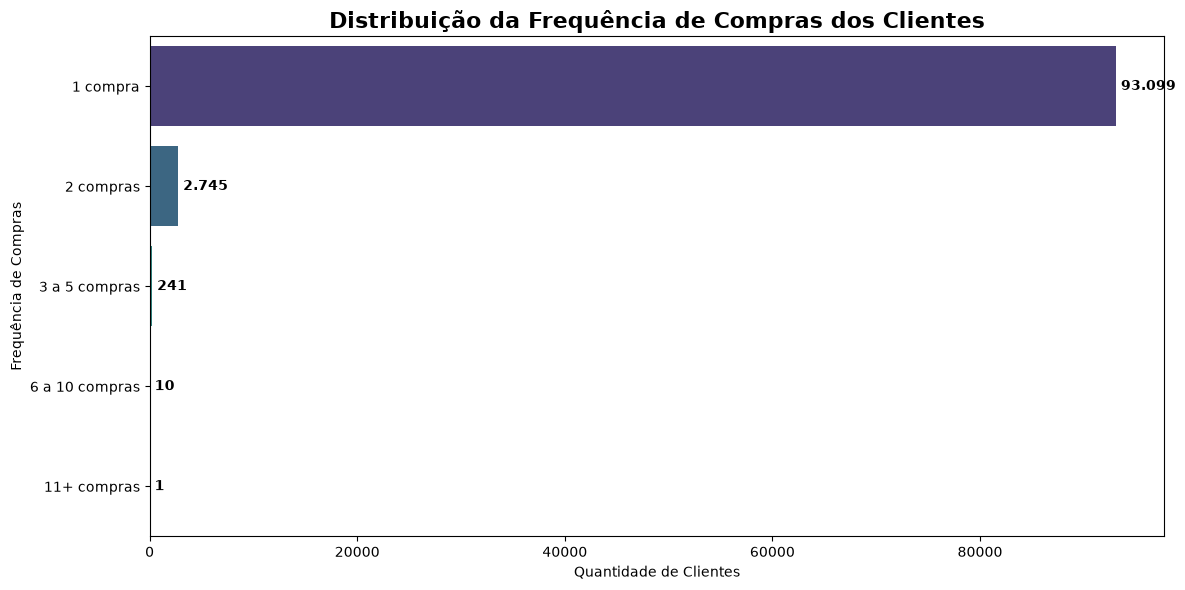

In [65]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=recorrencia_df,
    y="Categoria",
    x="Clientes",
    palette="viridis"
)

for i, valor in enumerate(recorrencia_df["Clientes"]):
    ax.text(
        valor,
        i,
        f" {valor:,}".replace(",", "."),
        va="center",
        fontweight="bold"
    )

plt.title(
    "Distribuição da Frequência de Compras dos Clientes",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Quantidade de Clientes")
plt.ylabel("Frequência de Compras")

plt.tight_layout()

plt.savefig(
    "../images/10_Distribuição_Frequência_Compras.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Avaliação da Visualização

A primeira visualização evidencia que a maior parte dos clientes realizou apenas uma compra durante o período analisado.

Embora o gráfico represente corretamente os dados, a grande concentração de clientes na categoria "1 compra" reduz significativamente a visibilidade das demais categorias, dificultando a análise do comportamento dos clientes recorrentes.

Para melhorar a interpretação dos resultados, será utilizada uma nova visualização focada na participação percentual de cada grupo de frequência de compra.

In [63]:
recorrencia_df["Percentual"] = (
    recorrencia_df["Clientes"]
    / recorrencia_df["Clientes"].sum()
    * 100
).round(2)

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_12256\3515838033.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


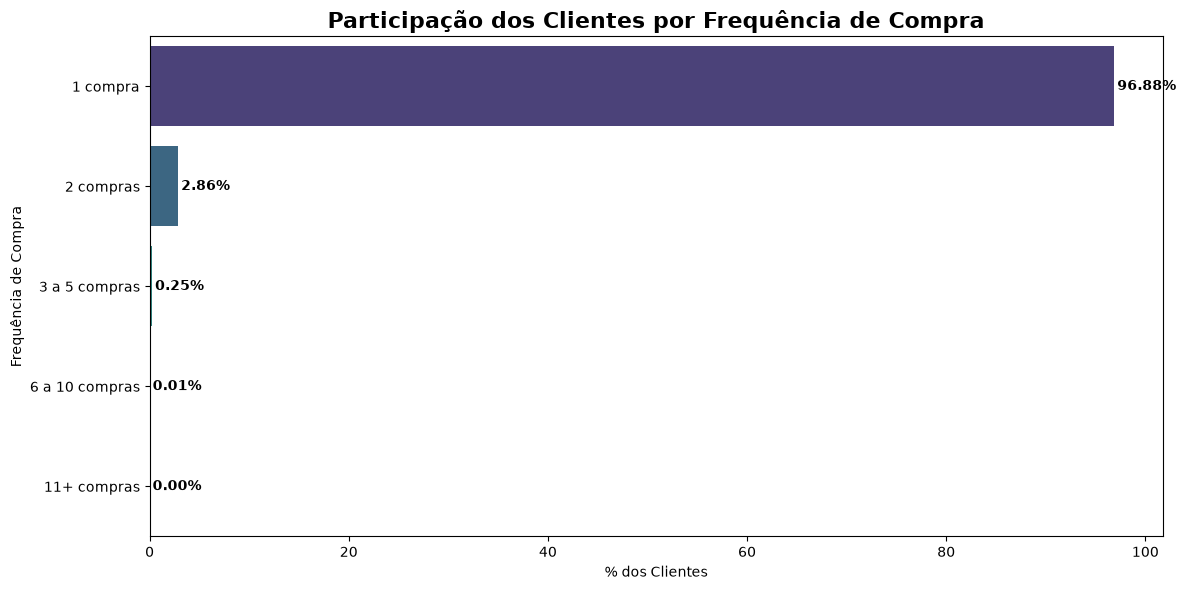

In [64]:
plt.figure(figsize=(12,6))

ax = sns.barplot(
    data=recorrencia_df,
    y="Categoria",
    x="Percentual",
    palette="viridis"
)

for i, valor in enumerate(recorrencia_df["Percentual"]):
    ax.text(
        valor + 0.3,
        i,
        f"{valor:.2f}%",
        va="center",
        fontweight="bold"
    )

plt.title(
    "Participação dos Clientes por Frequência de Compra",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("% dos Clientes")
plt.ylabel("Frequência de Compra")

plt.tight_layout()

plt.show()

## Refinamento da Visualização

A análise inicial da frequência de compras mostrou uma concentração muito elevada de clientes na categoria "1 compra".

Embora a visualização representasse corretamente os dados, a diferença entre as categorias dificultava a interpretação do comportamento dos clientes recorrentes, já que as demais categorias ficavam visualmente ofuscadas.

Para responder de forma mais objetiva à principal questão desta etapa, os clientes foram agrupados em duas categorias:

- Clientes que realizaram apenas uma compra;
- Clientes que realizaram compras recorrentes.

Essa abordagem permite avaliar de forma mais clara o peso da retenção de clientes na operação da plataforma.

In [66]:
compra_unica = (
    compras_por_cliente == 1
).sum()

compra_recorrente = (
    compras_por_cliente > 1
).sum()

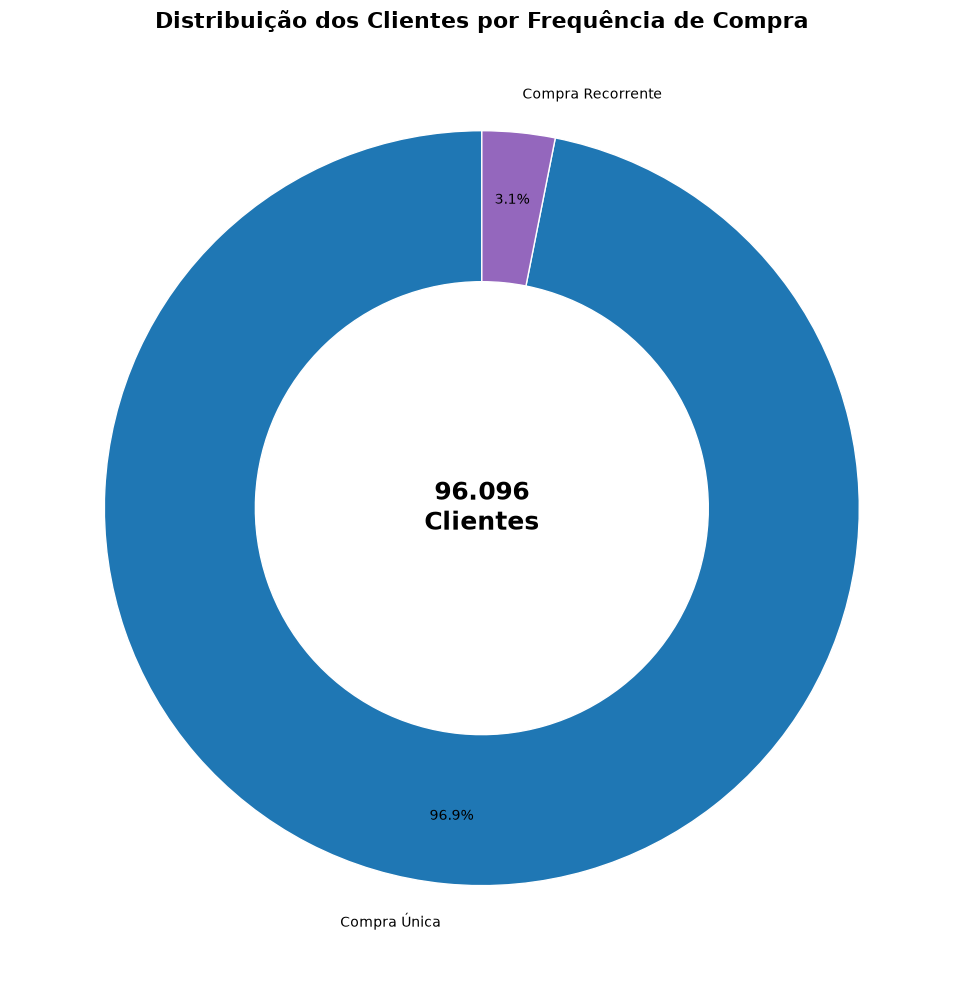

In [77]:
labels = [
    "Compra Única",
    "Compra Recorrente"
]

valores = [
    compra_unica,
    compra_recorrente
]

cores = [
    "#1f77b4",
    "#9467bd"
]

wedgeprops={
    "width": 0.15,
    "edgecolor": "white"
}

plt.figure(figsize=(10,10))

plt.text(
    0,
    0,
    "96.096\nClientes",
    ha="center",
    va="center",
    fontsize=18,
    fontweight="bold"
)


plt.pie(
    valores,
    labels=labels,
    colors=cores,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.82,
    wedgeprops={
        "width": 0.4,
        "edgecolor": "white"
    }
)

plt.title(
    "Distribuição dos Clientes por Frequência de Compra",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../images/11_Melhorado_Distribuição_Frequência_Compras.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Insight

A análise mostra que a esmagadora maioria dos clientes realizou apenas uma compra durante o período analisado.

Embora existam clientes recorrentes, a baixa participação desse grupo sugere que o crescimento observado entre 2016 e 2018 foi impulsionado principalmente pela aquisição de novos clientes, e não pela repetição de compras da base existente.

Esse resultado reforça a hipótese construída durante a análise temporal dos pedidos.

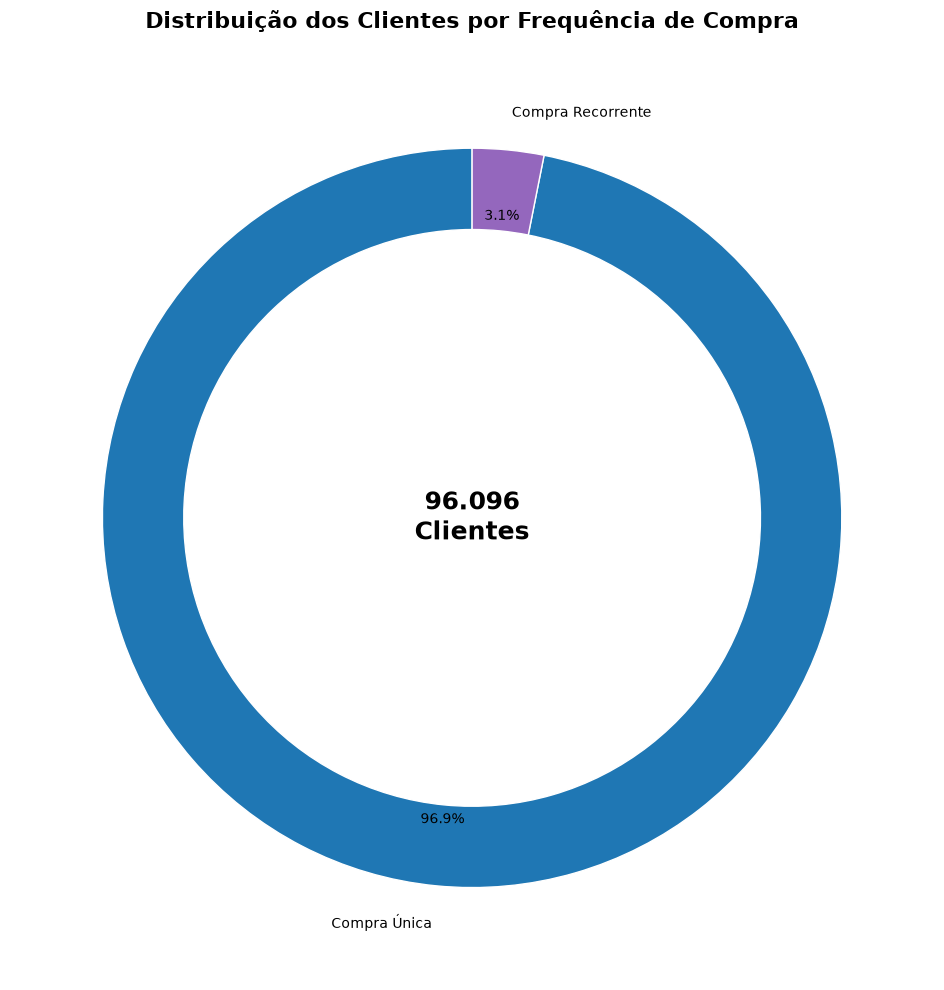

# Distribuição Geográfica dos Clientes

Após analisar o comportamento de compra dos clientes, o próximo passo consiste em identificar onde essa base está concentrada.

Esta análise permite compreender a distribuição geográfica da operação e identificar os estados com maior participação na plataforma.

In [79]:
clientes_por_estado = (
    customers["customer_state"]
    .value_counts()
)

In [80]:
print("📍 Top 10 Estados por Quantidade de Clientes\n")

for estado, quantidade in clientes_por_estado.head(10).items():

    percentual = (
        quantidade /
        clientes_por_estado.sum()
    ) * 100

    print(
        f"🏙️ {estado}: "
        f"{quantidade:,} clientes "
        f"({percentual:.2f}%)"
        .replace(",", ".")
    )

📍 Top 10 Estados por Quantidade de Clientes

🏙️ SP: 41.746 clientes (41.98%)
🏙️ RJ: 12.852 clientes (12.92%)
🏙️ MG: 11.635 clientes (11.70%)
🏙️ RS: 5.466 clientes (5.50%)
🏙️ PR: 5.045 clientes (5.07%)
🏙️ SC: 3.637 clientes (3.66%)
🏙️ BA: 3.380 clientes (3.40%)
🏙️ DF: 2.140 clientes (2.15%)
🏙️ ES: 2.033 clientes (2.04%)
🏙️ GO: 2.020 clientes (2.03%)


In [81]:
clientes_por_estado.head(10)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

# Distribuição Geográfica dos Clientes

Após analisar o comportamento de compra dos clientes, será investigada a distribuição geográfica da base de consumidores.

Esta análise permite identificar os estados com maior concentração de clientes e compreender a abrangência da operação da plataforma.


In [82]:
clientes_por_estado = (
    customers["customer_state"]
    .value_counts()
)

In [83]:
print("📍 Top 10 Estados por Quantidade de Clientes\n")

for estado, quantidade in clientes_por_estado.head(10).items():

    percentual = (
        quantidade /
        clientes_por_estado.sum()
    ) * 100

    print(
        f"🏙️ {estado}: "
        f"{quantidade:,} clientes "
        f"({percentual:.2f}%)"
        .replace(",", ".")
    )

📍 Top 10 Estados por Quantidade de Clientes

🏙️ SP: 41.746 clientes (41.98%)
🏙️ RJ: 12.852 clientes (12.92%)
🏙️ MG: 11.635 clientes (11.70%)
🏙️ RS: 5.466 clientes (5.50%)
🏙️ PR: 5.045 clientes (5.07%)
🏙️ SC: 3.637 clientes (3.66%)
🏙️ BA: 3.380 clientes (3.40%)
🏙️ DF: 2.140 clientes (2.15%)
🏙️ ES: 2.033 clientes (2.04%)
🏙️ GO: 2.020 clientes (2.03%)


## Distribuição Geográfica dos Clientes

Depois de analisar a frequência de compras dos clientes, foi realizada uma investigação sobre a distribuição geográfica da base de consumidores.

O objetivo desta etapa é identificar os estados com maior concentração de clientes e compreender como a operação está distribuída pelo território nacional.

Para facilitar a interpretação dos resultados, serão apresentados os 10 estados com maior número de clientes cadastrados na plataforma.

In [92]:
estados = {
    "SP": "São Paulo",
    "RJ": "Rio de Janeiro",
    "MG": "Minas Gerais",
    "RS": "Rio Grande do Sul",
    "PR": "Paraná",
    "SC": "Santa Catarina",
    "BA": "Bahia",
    "DF": "Distrito Federal",
    "ES": "Espírito Santo",
    "GO": "Goiás"
}

top10 = clientes_por_estado.head(10).copy()

top10.index = top10.index.map(estados)

print(top10.index)


Index(['São Paulo', 'Rio de Janeiro', 'Minas Gerais', 'Rio Grande do Sul',
       'Paraná', 'Santa Catarina', 'Bahia', 'Distrito Federal',
       'Espírito Santo', 'Goiás'],
      dtype='str', name='customer_state')


C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_12256\2518749316.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


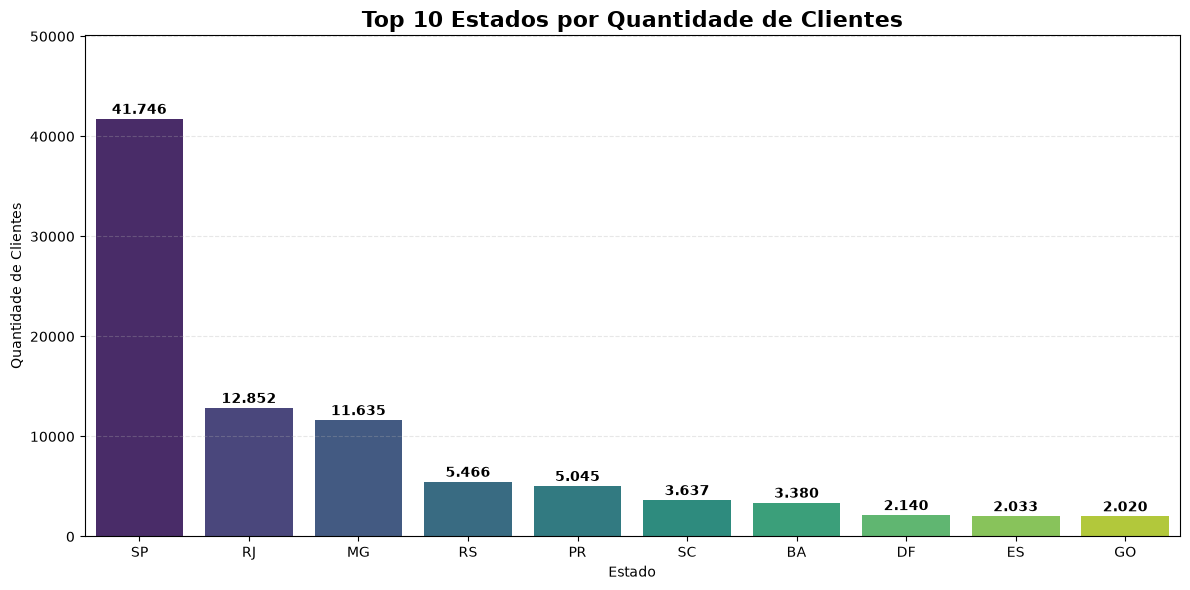

In [94]:
top10 = clientes_por_estado.head(10)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=top10.index,
    y=top10.values,
    palette="viridis"
)

for i, valor in enumerate(top10.values):
    ax.text(
        i,
        valor + 500,
        f"{valor:,}".replace(",", "."),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Top 10 Estados por Quantidade de Clientes",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Estado")
plt.ylabel("Quantidade de Clientes")

plt.ylim(
    0,
    max(top10.values) * 1.20
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "../images/12_clientes_por_estado.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

### Siglas dos Estados

- SP: São Paulo
- RJ: Rio de Janeiro
- MG: Minas Gerais
- RS: Rio Grande do Sul
- PR: Paraná
- SC: Santa Catarina
- BA: Bahia
- DF: Distrito Federal
- ES: Espírito Santo
- GO: Goiás

## Insight

A análise mostra uma forte concentração de clientes na região Sudeste do Brasil, com destaque para São Paulo, que possui mais de 41 mil clientes cadastrados.

Rio de Janeiro e Minas Gerais aparecem na sequência, reforçando a relevância econômica da região para a operação da plataforma.

Os resultados indicam que grande parte do crescimento observado nos anos analisados está concentrada em estados com elevada densidade populacional e forte atividade econômica.


# Conclusão Geral

A análise exploratória dos dados da Olist permitiu compreender diferentes aspectos da operação da plataforma, incluindo logística, evolução temporal dos pedidos e comportamento dos clientes.

Na perspectiva logística, observou\-se que a maior parte das entregas ocorreu entre 8 e 14 dias, enquanto entregas superiores a 60 dias representam uma parcela muito pequena dos pedidos. Também foi identificado que a operação apresenta predominância de entregas realizadas dentro ou antes do prazo prometido.

A análise temporal revelou um período de forte crescimento entre 2016 e 2017, seguido por uma fase de consolidação em 2018. Enquanto 2017 apresentou crescimento contínuo do volume de pedidos, 2018 manteve um patamar mais estável de demanda.

Ao investigar o comportamento dos clientes, foi observado que a grande maioria realizou apenas uma compra durante o período analisado. Esse resultado sugere que o crescimento da plataforma foi impulsionado principalmente pela aquisição de novos clientes, e não pela recorrência de compras da base existente.

Por fim, a distribuição geográfica mostrou elevada concentração de clientes na região Sudeste, com destaque para o estado de São Paulo, seguido por Rio de Janeiro e Minas Gerais.

De forma geral, os resultados indicam uma operação em expansão durante os primeiros anos analisados, sustentada por forte crescimento da base de clientes e por uma presença significativa nos principais centros econômicos do país.

